<a href="https://colab.research.google.com/github/JulTob/Optimization/blob/main/Practicas/P1_10_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#@title <font color="steelblue" size="+1"> Ejecutar configuración
!pip install cplex
!pip install docplex
from docplex.mp.model import Model
from docplex.mp.environment import Environment
env = Environment()
env.print_information()

import numpy as np
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.2/52.2 MB 47.5 MB/s  0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 4.9 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for docplex: filename=docplex-2.32.264-py3-none-any.whl size=703859 sha256=452064e81775fee1512bc57449d2ebfe850094f6515b2b91c573168864bf62ca
  Stored in directory: /root/.cache/pip/wheels/ba/11/de/5d0051be010658975fb2155006b4b8a818136d9f69ed20b4ba
Successfully built docplex
* system is: Linux 64bit
* Python version 3.13.16, located at: /usr/bin/python3
* docplex is present, version is 2.32.264
* CPLEX library is present, version is 22.2.0.0, located at: /usr/local/lib/python3.13/dist-packages
* pandas is present, version is 2.2.3


In [2]:
#@title <font color="steelblue" size="+1"> ALGORITMO SIMPLEX
def Simplex(obj_coeficientes,Matriz_restricciones,b_coeficientes,var):
  Matriz=Matriz_restricciones.copy()
  obj=obj_coeficientes.copy()
  b=b_coeficientes.copy()
  m=Matriz.shape[0]
  n=Matriz.shape[1]
  cr = np.zeros(n)
  v_b=np.zeros(m)
  n_b=m
  status=-1;
  # Variables básicas
  for  i in range(m):
    v_b[i]=n-m+i
  # Costos Reducidos
  for  i in range(n-m):
    cr[i]=obj[i]

  # Big M
  for  i in range(n-m):
    cr[i]=obj[i]
    for j in range(m):
      cr[i]=cr[i]-obj[n-m+j]*Matriz[j][i]

  z=0
  x_sol=np.zeros(n)
  for i in range(n):
    z=z+x_sol[i]*obj[i]

  #Imprimir tabla Simples
  def imprimir_Tabla(Iter):
    print ("Tabla {}: Basicas ".format(Iter), end="")
    for i in range(m):
      print (" {}".format(var[int(v_b[i])]), end="")
    print("\n--------------------------------------------------------------")
    print ("{:<5} | ".format(' cj '), end="")
    for i in range(0,n):
      print(" {:<5}  ".format(obj[i]) , end="" )
    print ("| {:<5}  ".format('  '))
    print("--------------------------------------------------------------")
    print ("{:<5} | ".format(' cB '), end="")
    for i in range(0,n):
      print(" {:<5}  ".format(var[i]), end="" )
    print ("| {:<5}  ".format(' b '))
    print("--------------------------------------------------------------")
    count=0
    for i in range(m):
      count=count+1
      if var_sale==i:
        print ("\033[1;32;47m{:<5} \033[0;0m| ".format(var[int(v_b[i])]), end="")
      if var_sale!=i:
        print ("{:<5} | ".format(var[int(v_b[i])]), end="")
      for j in range(n):
        print(" {:<5}  ".format(round(Matriz[count-1][j],2)), end="" )
      print("| {:<5}  ".format(round(b[count-1],2)), end="" )
      print("\n")
    print("--------------------------------------------------------------")
    print ("{:<5} | ".format("cr"), end="")
    for i in range(n):
      if i==var_entra:
        print("\033[1;32;47m {:<5}  \033[0;0m".format(round(cr[i],2)), end="" )
      if i!=var_entra:
        print(" {:<5}  ".format(round(cr[i],2)), end="" )




    print("| {:<5} ".format(round(z,2)), end="")
    print("\n")






  ###########################################################################
  ## Algoritmo
  ###########################################################################
  N_Iter=0
  while N_Iter<100:
    #variable que entra
    cr_max=0
    var_entra=-1
    # Calcular variable que entra en la Base
    for i in range(n):
      if cr[i]>cr_max:
        cr_max=cr[i]
        var_entra=i
    #print("La variable que entra es {}".format(var[var_entra]))
    if var_entra==-1:
      status=0
      break
    if var_entra>-1:
      # Calcular variable que sale de la Base
      ratio_min=1000000
      var_sale=-1
      for i in range(m):
        if Matriz[i][var_entra] > 0:
          if b[i]/Matriz[i][var_entra] < ratio_min and b[i]/Matriz[i][var_entra] >= 0:
            ratio_min= b[i]/Matriz[i][var_entra]
            var_sale=i
      #print("La variable que sale es {}-{}".format([var_sale],int(v_b[var_sale])))
      imprimir_Tabla(N_Iter)

      print("La variable que entra es {}".format(var[var_entra]))
      print("La variable que sale es {}".format(var[int(v_b[var_sale])]))

      if var_sale==-1:
        status=1
        break


      coef= Matriz[var_sale][var_entra]
      for j in range(n):
        Matriz[var_sale][j] = Matriz[var_sale][j]/coef
      b[var_sale]=b[var_sale]/coef

      for i in range(m):
        if i!=var_sale:
          coef=Matriz[i][var_entra]
          #print("coeficiente {}".format(coef))
          for j in range(n):
            Matriz[i][j]=Matriz[i][j]-(coef)*Matriz[var_sale][j]
          b[i]=b[i]-(coef)*b[var_sale]


      coef=cr[var_entra]
      for j in range(n):
        cr[j]=cr[j]-(coef)*Matriz[var_sale][j]




      # Actualizamos la base
      v_b[var_sale]=var_entra
      # Imprimir tabla y solución
      x_sol=np.zeros(n)
      for i in range(m):
        x_sol[int(v_b[i])]=b[i]


      z=0
      for j in range(n):
        z=z+x_sol[j]*obj[j]


      print("\n\n\n -------------------------------------------------------------")

      print("La solución en la iteración {} es : {}".format(N_Iter+1,z))
      for j in range(n):
        print(" {} = {} ".format(var[j],round(x_sol[j],2)))
      N_Iter=N_Iter+1
  # TERMINA ALGORITMO



  #print("--------------------------------------------------------------")
  #print("--------------------------------------------------------------")

  var_sale=-1
  var_entra=-1

  if status==0:
    imprimir_Tabla(N_Iter)

    print(" SOLUCIÓN ÓPTIMA:")
    print(" ÖPTIMO  : {}".format(z))
    for j in range(n):
      print(" {} = {} ".format(var[j],round(x_sol[j],2)))


  if status==1:
    print(" SOLUCIÓN NO ACOTADA:")

  count=0


## <font color="steelblue">**Lección Práctica 1**</font>

## <font color="steelblue">**1.1 Conceptos básicos en Programación Lineal**</font>

Al conjunto de todas las posibles alternativas que satisfacen las
restricciones del problema se le denomina <b>conjunto factible</b>, y a sus
elementos soluciones factibles. Además, a aquellas alternativas de entre
las factibles que son las mejores para el objetivo que se persigue se les
denomina <b>soluciones óptimas</b>. En un problema lineal el <b>conjunto factible</b>
es un <b>poliedro convexo</b>.

El número de alternativas a evaluar para buscar una solución óptima puede
ser muy grande (infinitas alternativas). Sin embargo, la estructura lineal de
los problemas conduce al siguiente resultado:

<font color="steelblue">**TEOREMA FUNDAMENTAL DE LA PROGRAMACIÓN LINEAL (TFPL)**</font>

Dado un problema lineal se satisface lo siguiente:

1. Si el **conjunto factible es no vacío** entonces este tiene **al menos un** **vértice**.

2. Si el problema tiene **solución óptima finita** entonces **al menos un** **vértice** es **solución óptima** del problema.

El **TFPL** implica que la búsqueda de la solución óptima se reduce a
buscar en un número finito de puntos que son los vértices de un
poliedro. Sin embargo, la tarea de hallar todos los vértices de un poliedro
tampoco es fácil en más de dos o tres dimensiones.

<ul>
<li>
Si el conjunto factible es vacío, es decir, no existen alternativas que
satisfacen todas las restricciones del problema lineal, entonces se dice que
el problema es infactible.</li>

<li>
El conjunto de soluciones óptimas puede ser un único punto, diciéndose
entonces que el problema tiene solución única.</li>

<li>
El conjunto de soluciones óptimas puede contener infinitas soluciones
(cuya estructura geométrica también es un poliedro).</li>

<li>
El problema lineal puede no tener solución finita, es decir, existe una
dirección en el conjunto factible a lo largo de la cual se puede mejorar
indefinidamente el valor de la función objetivo, en ese caso decimos que
tiene solución no acotada.</li></ul>

Consideremos un problema lineal en forma estándar:
    
    

$$ \max (\min)\,\, c' x $$

$$  s.a: \quad Ax = b   $$

$$  \qquad \quad \qquad x \geq 0_n   $$

Si tomamos $m$ columnas linealmente independientes de la matriz $A$,
entonces, reordenando las $n$ columnas si fuese necesario, se puede escribir
el problema lineal anterior de la siguiente forma:

$$ \max (\min)\,\, \quad  c_B' x_B + c_N' x_N $$

$$  s.a: \quad B x_B +  N x_N  = b   $$

$$  \qquad \quad \qquad x_B \geq 0_m   $$

$$  \qquad \quad \qquad x_N \geq 0_{n-m}   $$

donde $B$ es una matriz con $m$ columnas linealmente independientes y $N$
son las restantes columnas de la matriz $A$, y $x_B$ y $x_N$ son los vectores de las
variables asociadas a $B$ y $N$ respectivamente.

Si despejamos $x_B$ en función de $x_D$, entonces se tiene que

$$ x_B = B^{-1}b - B^{-1}Nx_N$$

A las soluciones del tipo $x_B = B^{–1}b$, $x_N = 0_{n–m}$, se les denomina **soluciones básicas**   y si, además, son factibles, esto es, verifican $x_B ≥ 0_m$, entonces se
les llama **soluciones básicas factibles**.

<font color="steelblue">**TEOREMA (RELACIÓN ENTRE LAS SOLUCIONES BÁSICAS)**</font>



Dado un problema lineal en forma estándar se satisface que toda
solución básica factible es un vértice del conjunto factible y
viceversa.

### <font color="steelblue">**Ejercicio 1**</font>
   

Resolver el problema utiliando las librerias de   CPLEX.
    
$ \max \,\, 2 x_1 +  x_2 + x_3 $

$  s.a: \quad   $

$  3 x_1 + x_2 +  x_3 + h_1 = 60     $

$   x_1 - x_2 + 2 x_3 + h_2 = 10     $


$  x_1, x_2, x_3, h_1, h_2 \geq  0     $



In [3]:
#@title <font color="steelblue" size="+1"> Ejercicio 1  (CPLEX)
beneficio=[2,1,1]
I= range(len(beneficio))
mdl = Model()
#variables
x_vars = [mdl.continuous_var(lb=None, ub=None, name=None ) for i in I]
#constraints
r1 = mdl.add_constraint( 3* x_vars[0] + x_vars[1] +    x_vars[2] <= 60 )
r2 = mdl.add_constraint(    x_vars[0] - x_vars[1] + 2* x_vars[2] <= 10 )
#objective
mdl.maximize(mdl.sum(   beneficio[i] * x_vars[i] for i in I) )
s = mdl.solve()
obj = mdl.objective_value
print("* best objective is: {:g}".format(obj))
for i in I:
    print(" La variable x{} toma el valor {}".format(i,x_vars[i].solution_value))
for i in I:
    print(" El costo reducido de la variable x{} es {}".format(i,mdl.reduced_costs(x_vars)[i]))
print(" El tiempod e resolución ha sido =",mdl.solve_details.time," segundos")
print(" Status =",mdl.solve_details.status)
print(" Status =",mdl.solve_details.status_code)
print(" Iterations =",mdl.solve_details.nb_iterations)



* best objective is: 60
 La variable x0 toma el valor 0
 La variable x1 toma el valor 60.0
 La variable x2 toma el valor 0
 El costo reducido de la variable x0 es -1.0
 El costo reducido de la variable x1 es 0
 El costo reducido de la variable x2 es 0
 El tiempod e resolución ha sido = 0.0007369518280029297  segundos
 Status = optimal
 Status = 1
 Iterations = 0



<font color="steelblue">**Costos reducidos**</font>

\begin{align}
z=& c'x= c_B' x_B + c_N' x_N = c_B'(B^{-1}b - B^{-1}Nx_N) + c_N' x_N =\\
  = & c_B'B^{-1}b+ (c_N'-c_B' B^{-1}N)x_N
\end{align}


El **costo reducido** de la variable $x_j$ no básica, es:

$$ \overline{c}_j = c_j - c'_BB^{-1}A_j   $$




### <font color="steelblue">**El algoritmo Simplex**</font>


Si partimos de una solución básica factible, ésta podemos escribirla, como
antes, de la siguiente forma:

$$ x_B = B^{-1}b - B^{-1}Nx_N$$

Por lo tanto, el valor de la función objetivo asociado a dicha solución básica
factible vendrá dado por:

$$ c' x = c_B' x_B + c_N' x_N= d_B' B^{-1}b + (c_N'- c_B' B^{-1}N )x_N$$

De la última expresión se desprende que para cada variable $x_j$ de $N$, se
tiene asociado un valor, que denominaremos **coste reducido** de la variable
y denotaremos por $\overline{c}_j$. Este coste reducido se interpreta como la contribución
de la variable $x_j$ a la función objetivo si dicha variable pasase a tomar el
valor 1. Esta contribución es neta, es decir, no coincide con su coeficiente
en la función objetivo sino que está reducido por lo que ya están
contribuyendo las variables en $B$.



 <font color="steelblue">**Test optimalidad**</font>

Dado un problema lineal en forma estándar y una solución básica factible $x_B$
para él, se satisface lo siguiente:
    
1. En un problema de maximización una solución básica factible es óptima
si se cumple que

$$  (c_N'- c_B' B^{-1}N ) =\overline{c}_N \leq 0_{n-m}$$

2. En un problema de minimización una solución básica factible es óptima si
se cumple que

$$  (c_N'- c_B' B^{-1}N ) =\overline{c}_N \geq 0_{n-m}$$





 <font color="steelblue">**Mejorando la solución**</font>

  Supongamos que en un problema de minimización, $ \overline{c}_j = c_j - c'_BB^{-1}A_j \leq 0  $, entonces, sea $d_B=-B^{-1}A_j$, $d_j=1$, $d_k=0$ para $k\in N\setminus \{j\}$.

  Sea $y=x+\theta d$, $\theta >0$, entonces

  \begin{align}
  c'y-c'x=& \theta c'd\\
         =& \theta (c'_Bd_B+c_jd_j)\\
         =&  \theta (c_j-c'_BB^{-1}A_j)\\
         =&\theta \overline{c}_j < 0
  \end{align}

Por lo tanto, la solución $y$ mejora a la  solución $x$.
  

- Dado que $Ad=0 $, se cumple que $Ay=Ax=b$, por lo tanto, $y+\theta d $ es factible.

- Si $d\geq 0$ se tiene que $x+\theta d \geq 0$, por lo tanto el problema es no acotado.

- Si $d_i \leq 0,$ entonces

$$x_i+\theta d_i\geq 0 \rightarrow \theta \leq \frac{-x_i}{d_i}\rightarrow \theta^* =\min_{i:d_i<0}\left\{\frac{-x_i}{d_i}\right\}$$



#### <font color="steelblue">**El algoritmo Simplex**</font>

 1- Comenzar con una solución básica inicial $x$, $B$, $N$.

 2.- Calcular $\overline{c}_j=c_j-c_BB^{-1}A_j$
  * Si $ \overline{c}_j \geq 0$, $x$ solución óptima.
  * En otro caso, selecciona $j$: $ \overline{c}_j \leq 0$

 3. Calcular $u=-d=B^{-1}A_j$
  * Si $u\leq 0$, problema no acotado.
  * Si $u>0$, calcular $\theta^*=\min_{i: u_i\geq 0}\left\{\frac{-x_i}{d_i}\right\}$  

 4. Reemplazar en la Base $B$, $A_i$ por $A_j$




![transporte](https://drive.google.com/thumbnail?id=161Q90MYXuS2c-nuNqQOvlZZc7xtsllJ7&sz=h200)


- Si cada solución básica factible es no degenerada, entonces el algoritmo Simplex termina en un número finito de pasos.

- Si $\theta^*$ es cero, o $\theta^*>0$ pero con empates, la solcuión básica facgible es degenerada. No está garantizada la convergencia del algoritmo simplex, puede caer en ciclos.




 ### <font color="steelblue">**Ejemplo 2**</font>

Forma canónica:

\begin{align}
 \max & 8x+10y\\
 s.a. &\\
&0.5 x + y \leq 10\\
&8x+8y  \leq110\\
&x, y\geq 0
\end{align}

Forma estándar:

\begin{align}
 \max & 8x+10y\\
 s.a. &\\
&0.5 x + y + h_1 = 10\\
&8x+8y + h_2 = 110\\
&x, y, h_1 ,h_2\geq 0\
\end{align}



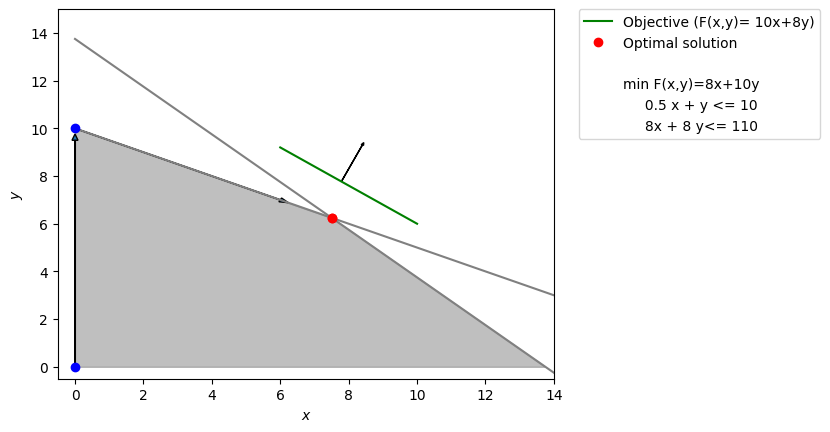

In [4]:
#@title <font color="steelblue" size="+1"> Ejemplo 2
#Leader con todas las restricciones
mdl = Model()
#Variables
x = [mdl.continuous_var(lb=0, ub=None, name="x_%d"%i ) for i in range(1)]
y = [mdl.continuous_var(lb=0, ub=None, name="y_%d"%i ) for i in range(1)]
# f. objetivo
mdl.minimize( x[0] + 6*y[0])
# restricciones
r1=mdl.add_constraint( 0.5*x[0] + y[0] <= 10)
r2=mdl.add_constraint( 8*x[0] +8*y[0] <= 110)
s = mdl.solve()
obj = mdl.objective_value
#print(" La variable x toma el valor {}".format(x[0].solution_value))
#print(" La variable y toma el valor {}".format(y[0].solution_value))
#print(" Objetivo Leader  {:g}".format(obj))
# Dibujar región factible
x=0.0
x_sol=[]
y_sol=[]
x = np.linspace(0, 16, 100)
y1 =  -.5*(x) +10.
y2 =  -x+110/8.
# Make plot
x_temp = np.linspace(6, 10, 100)
F =  -8*x_temp/10. +14
plt.plot(x_temp, F,color="green", label="Objective (F(x,y)= 10x+8y)")
plt.arrow(7.8,7.8, .6, 1.5,head_width=.075)
x_temp = np.linspace(3.5, 4.5, 100)
f =  0*x_temp  +4

plt.plot(x, y1,color='gray')
plt.plot(x, y2,color='gray')
plt.xlim((-0.5, 14))
plt.ylim((-0.5, 15))
plt.xlabel(r'$x$')
plt.ylabel(r'$y$')
# Fill feasible region
y_max = np.minimum(y1, y2)
y_min = np.maximum(0,0)
plt.fill_between(x, y_min, y_max, where=y_max>y_min, color='grey', alpha=0.5)
plt.plot(7.5,6.25,marker='o',color='red')
plt.plot(7.5,6.25,marker='o',color='red',label='Optimal solution ',linestyle='none')

plt.plot(0,0,marker='o',color='blue')
plt.arrow(0,0, 0, 9.5,head_width=.175)
plt.plot(0,10,marker='o',color='blue')
plt.arrow(0,10, 6, -3,head_width=.175)



plt.plot(-1,-1,marker='o',color='white',label=("               "),linestyle='none')
plt.plot(-1,-1,marker='o',color='white',label=("min F(x,y)=8x+10y"),linestyle='none')
plt.plot(-1,-1,marker='o',color='white',label=("     0.5 x + y <= 10"),linestyle='none')
plt.plot(-1,-1,marker='o',color='white',label=("     8x + 8 y<= 110"),linestyle='none')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

In [5]:
#@title <font color="steelblue" size="+1"> Ejemplo 2 (CPLEX)
# INTRODUCIR PROBLEMA
#from numpy.lib.index_tricks import c_
# Algoritmo Simplex
import numpy as np
obj_coeficientes = np.array([8,10,0,0])
Matriz_restricciones =np.array([[0.5,1,1,0],
         [8,8,0,1]])
b_coeficientes=np.array([10.,110.])
var_names=np.array(["x","y","h1","h2"])
Simplex(obj_coeficientes,Matriz_restricciones,b_coeficientes,var_names)

Tabla 0: Basicas  h1 h2
--------------------------------------------------------------
 cj   |  8       10      0       0      |        
--------------------------------------------------------------
 cB   |  x       y       h1      h2     |  b     
--------------------------------------------------------------
h1    |  0.5     1.0     1.0     0.0    | 10.0   

h2    |  8.0     8.0     0.0     1.0    | 110.0  

--------------------------------------------------------------
cr    |  8.0     10.0    0.0     0.0    | 0.0   

La variable que entra es y
La variable que sale es h1



 -------------------------------------------------------------
La solución en la iteración 1 es : 100.0
 x = 0.0 
 y = 10.0 
 h1 = 0.0 
 h2 = 30.0 
Tabla 1: Basicas  y h2
--------------------------------------------------------------
 cj   |  8       10      0       0      |        
--------------------------------------------------------------
 cB   |  x       y       h1      h2     |  b     
------------------

<blockquote>

<b> Conjetura de Hirsch (1957)</b>
Si un poliedro está definido por $m$ desigualdades
lineales en $n$ variables siempre ha de ser posible
viajar de cualquier vértice a cualquier otro vértice
recorriendo como mucho $m-n$ aristas.

El diámetro de un poliedro es la máxima distancia entre dos vértices del poliedro.

<b> Contraejemplo Francisco Santos (2010)</b>


Politopo 43-dimensional de 86 caras con un diámetro de
más de 43

<b> Sabemos:</b>

- La máxima distancia entre dos vértices es:

    $$ distancia\ maxima \geq m-n + \left\lfloor\frac{n}{5}\right\rfloor$$   

    $$ distancia\ maxima \le m^{1+\log_2 n} = (2n)^{\log_2 m}$$



<blockquote>

<b>Complejidad computacional del Símplex</b>

* Cada iteración requiere alrededor de $m(n-m)+(m+1)^2$ multiplicaciones y
  $m(m+1)$ sumas o restas: $O(mn)$ en los dos casos pues $n >> m$.
        
* El número de puntos extremos de un programa lineal en forma estándar con $n$ variables y $m$ condiciones es $C(n,m)$.  Si $n \geq 2m$, se tiene que
    
$$C(n,m)=\frac{n!}{m!(n-m)!}\geq 2^m$$
    

De acuerdo con esto, en el peor de los casos, parece lógico temerse un número
de iteraciones exponencial.   
    

<blockquote>

Un problema clásico es el estudiado por <b>Klee y Minty</b> [1972]:

$ \max \,\,  x_n $

$  s.a: \quad   $

$\qquad   0 \leq x_1 \leq 1     $

$  \qquad   \delta x_{i-1} \leq x_i \leq 1 - \delta x_{i-1}, \quad i=2,...,n, \quad 0<\delta < 1/2   $


$\qquad   x_i \geq 0, \quad i=1,...,n     $


Tiene $2^n$ puntos extremos. Para $n=2$ y $n=3$ es el de la figura siguiente.

![Klee_Minty.png](https://drive.google.com/thumbnail?id=1ZhyzhK2fxQe4B4xckUczk0JmBSLo6nj3&sz=h450)


Comenzando en $x=0$ (factible), el método recorrerá los $2^n$ puntos extremos.


<blockquote>

* La práctica de los últimos cincuenta años ha permitido constatar que los casos extremos, como el ejemplo de Klee y Minty, rara vez ocurren en la realidad.

* Grosso modo, en problemas de tamaño moderado, el método Símplex requiere un número de iteraciones real comprendido entre $4m$ y $6m$.

* En problemas muy grandes, el número de iteraciones que cabe esperar llevar a cabo para resolverlos es $\alpha m$, donde $e^{\alpha} < \log_2 (2+n/m)$.

                                                 
En resumen, la complejidad computacional práctica esperada del método
Símplex es del $O(m^2 n)$.


## <font color="steelblue">**1.2 Dualidad en programación lineal**</font>

La dualidad consiste, básicamente, en asociar a un problema lineal, que
denominaremos <b>problema primal</b>, un problema lineal auxiliar, que
denominaremos <b>problema dual</b>, que se define directa y sistemáticamente a
partir del problema primal. El problema dual viene a ser el problema
“traspuesto” del problema primal.

En este sentido se tendrá que:

<blockquote><ul>
<li>
Los coeficientes de la función objetivo del problema primal pasan a ser los
términos independientes de las restricciones en el problema dual.</li>

<li>
Los términos independientes del problema primal pasan a jugar el papel
de coeficientes de la función objetivo del dual.</li>

<li>
La matriz de restricciones para el dual es la traspuesta del primal.
</li></ul></blockquote>

  
La dualidad tiene gran importancia por las siguientes razones:

<blockquote><ul>
<li>
Por las posibilidades que abre en el desarrollo teórico de la programación
lineal.</li>

<li>
La dualidad es fundamental para el análisis de sensibilidad.</li>

<li>    
Permite en ciertas ocasiones ventajas computacionales para la obtención
de soluciones óptimas.</li>

<li>
Es útil para el desarrollo de métodos de optimización matemática.</li>
    
<li>
Origina interesantes interpretaciones económicas e información relevante
    para la toma de decisiones.</li></ul></blockquote>



<blockquote>
    
![Dualidad2](https://drive.google.com/thumbnail?id=1DrIAagPqLhhWBD-QCVw22l9gQ9eY6hRu&sz=h450)



<blockquote>

  $
\begin{matrix}
\text{Problema Primal} && \text{Problema Dual}   \\ \hline
 \max \,\, c^T x  &&  \min \,\, b^T y   \\
s.a: \quad Ax \leq b && s.a: \quad A^Ty \geq c  \\
  \qquad  \qquad x \geq 0_n     &&   \qquad  \qquad y \geq 0_m  \\ \hline
\end{matrix}
$



  ![Primal_dual](https://drive.google.com/thumbnail?id=1-Gc475MwsJkcT7t8a-4zJhrQGBqh5VJO&sz=h250)    
    

\begin{align}
PRIMAL && DUAL\\ \hline
\min \, c'x \qquad && \max \, y'b \quad \\
s.a \quad a_j' x \geq b_j && s.a \quad y_j\geq 0  \\
 \quad a_j' x \leq b_j &&  \quad y_j\leq 0  \\
 \quad a_j' x = b_j &&  \quad y_j \, free  \\
 x_i \geq  0 &&  \quad y'A_i\leq c_i\\
 x_i \leq  0 &&  \quad y'A_i\geq c_i\\
 x_i \, free   &&  \quad y'A_i = c_i\\
\end{align}
    

   

<blockquote>

 <font color="steelblue">**TEOREMA DE LA DUALIDAD DÉBIL**</font>

Dado un problema lineal y su dual, sea $x$ una solución factible del
problema primal e $y$ una solución factible del problema dual, entonces se
verifica lo siguiente:

Si el objetivo del problema primal es maximizar entonces se tiene que:

$$y' b ≥ c' x $$

Si el objetivo del problema primal es minimizar entonces se tiene que:

$$ y' b ≤ c' x $$

<blockquote>

 <font color="steelblue">**TEOREMA DE LA DUALIDAD FUERTE**</font>


Sean un problema lineal y su dual. Entonces se satisface lo siguiente:

<ul>
<li>
Si uno de los dos problemas tiene valor óptimo no acotado, entonces el
otro es infactible.</li>

<li>    
El problema primal tiene valor óptimo finito si, y sólo si, el problema dual
    tiene valor óptimo finito. Además, ambos valores óptimos coinciden.</li></ul></blockquote>
    

<blockquote>
    
**COMENTARIO**:

El T. de la dualidad fuerte no establece que si un problema lineal es
infactible su dual sea no acotado, puede ocurrir que su dual sea infactible
también.

Por ejemplo: $ \quad \min \quad –x \,\quad  s.a: \quad 0 x ≥ 1, x ≥ 0$

<blockquote>


| |  Óptimo finito        | No acotado  |Infactible   |  
|:-----| :--------------- | :------:| :-----------:|  
| **Óptimo finito** |   ![1/3](https://img.shields.io/static/v1?label=&message=★&color=FDFEFE&style=plastic) | | |
| **No acotado** |  |  | ![1/3](https://img.shields.io/static/v1?label=&message=★&color=FDFEFE&style=plastic) |  
| **Infactible** |  | ![1/3](https://img.shields.io/static/v1?label=&message=★&color=FDFEFE&style=plastic)  | ![1/3](https://img.shields.io/static/v1?label=&message=★&color=FDFEFE&style=plastic) |  

<blockquote>

 <font color="steelblue">**COROLARIO**</font>


Sean un problema lineal y su dual. Si $[B|D]$ es una descomposición de la
matriz $A$, que da una solución óptima para el problema primal entonces, se
verifica que una solución óptima para el dual viene dada por

$$ y^* = c'_B B^{-1}$$

<blockquote>

 <font color="steelblue">**INTERPRETACIÓN DE LAS VARIABLES DUALES**</font>


Dada la información que proporcionan las variables duales óptimas acerca
de la variación experimentada en el valor óptimo de un problema cuando
variamos el término independiente de la restricción asociada, dichas
variables suelen recibir el nombre de precios sombra o precios duales o
costes de oportunidad.

Las variables duales nos permiten determinar bien el precio que estamos
dispuestos a pagar por aumentar el conjunto factible variando en una
unidad el correspondiente término independiente, o bien el precio que
estamos dispuestos a recibir por disminuir el conjunto factible variando
en una unidad el correspondiente término independiente.

<blockquote>

 <font color="steelblue">**Holguras complementarias**</font>


Sean un problema lineal y su dual. $x$ e $y$ son soluciones óptimas, si y solo si:

- $ y_j(a_j'x-bj)=0, \forall j$
- $x_i(c_i-y'A_i)=0, \forall i$




dado un problema de optimización y su dual:

$
\begin{matrix}
\text{Problema Primal} && \text{Problema Dual}   \\ \hline
 \max \,\, c^T x  &&  \min \,\, b' y   \\
s.a: \quad Ax \leq b && s.a: \quad A'y \geq c  \\
  \qquad  \qquad x \geq 0_n     &&   \qquad  \qquad y \geq 0_m  \\ \hline
\end{matrix}
$


El problema de optimización es equivalente al sistema:


\begin{align}
  Ax \leq &b  \\
  x\geq & 0\\
   A'y - c \geq& 0\\
  x'(A'y - c)=&0
\end{align}

 ### <font color="steelblue">**Ejemplo 3**</font>


Una petroquímica de la cuenca mediterránea se dedica a producir
plástico para botellas (PET-botella) y fibra textil (PET-fibra) a partir de PTA
(ácido tereftáltico puro) y de EtG (etilen-Glicol). Las cantidades de cada
producto (en Tm.) que son necesarias para producir una tonelada de
cada uno de estos derivados vienen dadas por:


|              | PET-botella   | PET-fibra    |
|-------------------|-------------|-----|
| PTA   | 0.966    | 0.912             |
| EtG   | 0.365       | 0.344             |

    
    
La venta en el mercado de plástico da un beneficio de 60 € por Tm., mientras
que la venta de fibra textil da un beneficio de 50 €/Tm.
Teniendo en cuenta que la petrolera dispone de 260.000 Tm. de PTA y
150.000 Tm. de EtG, ¿cuáles serían sus niveles óptimos de producción de
fibra textil y de plástico?    
    
Si definimos $x_1$= Tm fabricadas de plástico para botelas, y $x_2$= Tm fabricadas de fibra Textil      
    
La respuesta a la pregunta anterior vendría dada por la solución del problema:
    
$ \max 60 x_1 + 50 x_2$
    
$ s.a: $
    
$ \quad  0.966 x_1 + 0.912 x_2 \leq 260000 $
    
$ \quad  0.365  x_1 + 0.344 x_2 \leq 150000 $
    
$ x_1, x_2 \geq 0$    
    
Solución:
    
$x_1^* = 269151.139$

$x_2^* = 0$
    
Beneficio: $16149068.32$

 ### <font color="steelblue">**Ejemplo 3 cont.**</font>


La industria petroquímica en la cuenca Mediterránea está controlada por
una gran compañía que necesita PTA y EtG para su proceso de
producción. El gerente quiere persuadir a la pequeña petroquímica para
que abandone su proceso productivo y le venda directamente sus
existencias.
    
Al gerente se le plantea el problema de determinar el precio de compra
que debe ofrecer a la pequeña de manera que no sólo esa compra le
salga lo más barata posible, sino que a la pequeña le interese vender: lo
que recibe por dejar de producir una unidad de cada uno de sus
productos no sea inferior a lo que obtendría con su venta directa en el
mercado.

¿Qué problema debe resolver el gerente para determinar dichos
precios?

$y_1$, precio de PTA (en € por Tm), $y_2$ precio de EtG (en € por Tm)  

$ \min 260000 y_1 + 150000 y_2$
    
$ s.a: $
    
$ \quad  0.966 y_1 + 0.365 y_2 \geq 60 $
    
$ \quad  0.912  y_1 + 0.344 y_2 \geq 50 $
    
$ y_1, y_2 \geq 0$    
    
Solución:
    
$y_1^* = 62.11$

$y_2^* = 0$
    
Beneficio: $16149068.32$  

    
 **Cuestiones**:

¿Cuánto aumentaría el beneficio de la pequeña empresa petroquímica si
se incrementaran sus recursos de PTA y EtG en una unidad,
respectivamente?

¿Qué precio de compra de PTA y EtG debe ofrecer la compañía grande a
la pequeña de manera que no sólo esa compra le salga lo más barata
posible, sino que a la pequeña le interese vender?    

In [6]:
#@title <font color="steelblue" size="+1"> Ejemplo 3  (CPLEX)
beneficio=[60,50]
I= range(len(beneficio))
mdl = Model()
#variables
x_vars = [mdl.continuous_var(lb=None, ub=None, name=None ) for i in I]
#constraints
r1 = mdl.add_constraint( .966 * x_vars[0] + .912 * x_vars[1]  <= 260000 )
r2 = mdl.add_constraint( .365 * x_vars[0] + .344 * x_vars[1]  <= 150000 )
#objective
mdl.maximize(mdl.sum(   beneficio[i] * x_vars[i] for i in I) )
s = mdl.solve(log_output=True)
obj = mdl.objective_value
print("* best objective is: {:g}".format(obj))
for i in I:
    print(" La variable x{} toma el valor {}".format(i,x_vars[i].solution_value))
#for i in I:
#    print(" El costo reducido de la variable x{} es {}".format(i,mdl.reduced_costs(x_vars)[i]))
print(" la variable dual de la primera restricicón es {}".format(r1.dual_value))
print(" la variable dual de la segunda restricicón es {}".format(r2.dual_value))
print(" El tiempod e resolución ha sido =",mdl.solve_details.time," segundos")
print(" Status =",mdl.solve_details.status)
print(" Status =",mdl.solve_details.status_code)
print(" Iterations =",mdl.solve_details.nb_iterations)



Version identifier: 22.2.0.0 | 2026-07-01 | 7cae668b4
CPXPARAM_Read_DataCheck                          1
Tried aggregator 1 time.
No LP presolve or aggregator reductions.
Presolve time = 0.00 sec. (0.00 ticks)

Iteration log . . .
Iteration:     1   Dual infeasibility =             0.000000
* best objective is: 1.61491e+07
 La variable x0 toma el valor 269151.13871635613
 La variable x1 toma el valor 0
 la variable dual de la primera restricicón es 62.11180124223603
 la variable dual de la segunda restricicón es 0
 El tiempod e resolución ha sido = 0.008767127990722656  segundos
 Status = optimal
 Status = 1
 Iterations = 0
